In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score
)

In [3]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

df = pd.read_csv(url)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.shape

(5000, 9)

In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
target = 'converted'

categorical = [
    'lead_source',
    'industry',
    'employment_status',
    'location'
]

numerical = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

In [7]:
df[categorical] = df[categorical].fillna('NA')

df[numerical] = df[numerical].fillna(0.0)

In [8]:
df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

In [9]:
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [10]:
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

In [11]:
df_train = df_train.drop(columns=[target])
df_val = df_val.drop(columns=[target])
df_test = df_test.drop(columns=[target])

Q1

In [12]:
for feature in numerical:

    auc = roc_auc_score(
        y_train,
        df_train[feature]
    )

    if auc < 0.5:
        auc = roc_auc_score(
            y_train,
            -df_train[feature]
        )

    print(feature, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


Q2

In [13]:
LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [14]:
train_dicts = df_train[categorical + numerical].to_dict(
    orient='records'
)

val_dicts = df_val[categorical + numerical].to_dict(
    orient='records'
)

In [15]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [16]:
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [17]:
y_pred = model.predict_proba(X_val)[:, 1]

In [18]:
auc = roc_auc_score(y_val, y_pred)

round(auc, 3)

0.732

Q3

In [19]:
thresholds = np.linspace(0, 1, 101)

results = []

for threshold in thresholds:

    y_pred_binary = (y_pred >= threshold).astype(int)

    precision = precision_score(
        y_val,
        y_pred_binary,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_binary,
        zero_division=0
    )

    results.append((
        threshold,
        precision,
        recall
    ))

In [20]:
df_thresholds = pd.DataFrame(
    results,
    columns=['threshold', 'precision', 'recall']
)

df_thresholds.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


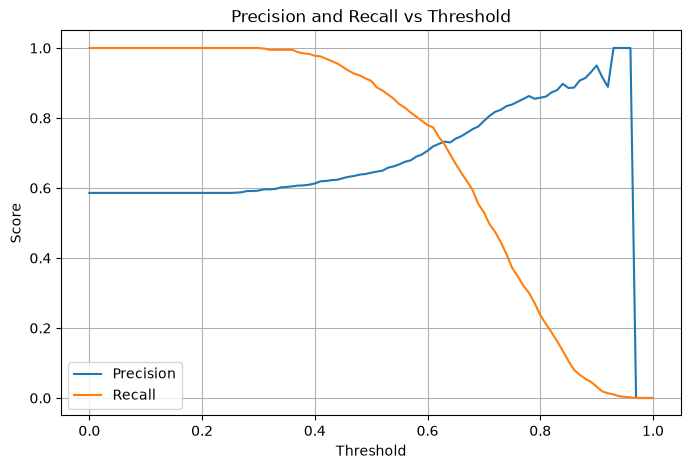

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_thresholds['threshold'],
    df_thresholds['precision'],
    label='Precision'
)

plt.plot(
    df_thresholds['threshold'],
    df_thresholds['recall'],
    label='Recall'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)

plt.show()

In [22]:
df_pr = df_thresholds[
    ~(
        (df_thresholds['precision'] == 0) &
        (df_thresholds['recall'] == 0)
    )
].copy()

df_pr['difference'] = abs(
    df_pr['precision'] - df_pr['recall']
)

df_pr.sort_values(
    ['difference', 'threshold']
).head(10)

,threshold,precision,recall,difference
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079
60,0.60,0.706337,0.779863,0.073527
59,0.59,0.695652,0.791809,0.096157
66,0.66,0.748016,0.643345,0.104671
58,0.58,0.689605,0.803754,0.114150
57,0.57,0.678977,0.815700,0.136722


Q4

In [23]:
p = df_thresholds['precision'].to_numpy()
r = df_thresholds['recall'].to_numpy()

denominator = p + r

df_thresholds['f1'] = np.divide(
    2 * p * r,
    denominator,
    out=np.zeros_like(denominator),
    where=denominator != 0
)

In [24]:
df_thresholds.sort_values(
    'f1',
    ascending=False
).head(10)

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717
46,0.46,0.632065,0.935154,0.754301
48,0.48,0.638298,0.921502,0.754190
40,0.40,0.612834,0.977816,0.753452
47,0.47,0.634346,0.926621,0.753121
50,0.50,0.643636,0.906143,0.752658


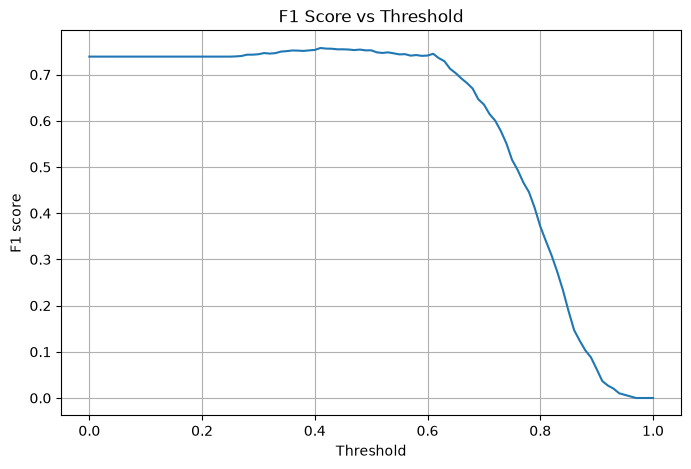

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_thresholds['threshold'],
    df_thresholds['f1']
)

plt.xlabel('Threshold')
plt.ylabel('F1 score')
plt.title('F1 Score vs Threshold')
plt.grid(True)

plt.show()

Q5

In [26]:
KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

KFold(n_splits=5, random_state=1, shuffle=True)

In [27]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

In [28]:
y_full_train = df_full_train[target].values

In [29]:
scores = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(df_full_train),
    start=1
):

    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold[target].values
    y_val_fold = df_val_fold[target].values

    train_dicts_fold = df_train_fold[
        categorical + numerical
    ].to_dict(orient='records')

    val_dicts_fold = df_val_fold[
        categorical + numerical
    ].to_dict(orient='records')

    dv_fold = DictVectorizer(sparse=False)

    X_train_fold = dv_fold.fit_transform(
        train_dicts_fold
    )

    X_val_fold = dv_fold.transform(
        val_dicts_fold
    )

    model_fold = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model_fold.fit(
        X_train_fold,
        y_train_fold
    )

    y_pred_fold = model_fold.predict_proba(
        X_val_fold
    )[:, 1]

    score = roc_auc_score(
        y_val_fold,
        y_pred_fold
    )

    scores.append(score)

    print(f'Fold {fold}: {score:.3f}')

Fold 1: 0.731
Fold 2: 0.730
Fold 3: 0.736
Fold 4: 0.741
Fold 5: 0.721


In [30]:
std = np.std(scores)

round(std, 3)

np.float64(0.007)

Q6

In [31]:
C_values = [0.000001, 0.001, 1]

In [32]:
C_values = [0.000001, 0.001, 1]

results = []

for C in C_values:

    scores_C = []

    for train_idx, val_idx in kf.split(df_full_train):

        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold[target].values
        y_val_fold = df_val_fold[target].values

        train_dicts_fold = df_train_fold[
            categorical + numerical
        ].to_dict(orient='records')

        val_dicts_fold = df_val_fold[
            categorical + numerical
        ].to_dict(orient='records')

        dv_fold = DictVectorizer(sparse=False)

        X_train_fold = dv_fold.fit_transform(
            train_dicts_fold
        )

        X_val_fold = dv_fold.transform(
            val_dicts_fold
        )

        model_fold = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model_fold.fit(
            X_train_fold,
            y_train_fold
        )

        y_pred_fold = model_fold.predict_proba(
            X_val_fold
        )[:, 1]

        score = roc_auc_score(
            y_val_fold,
            y_pred_fold
        )

        scores_C.append(score)

    mean_auc = np.mean(scores_C)
    std_auc = np.std(scores_C)

    results.append({
        'C': C,
        'mean_auc': mean_auc,
        'std_auc': std_auc
    })

    print(
        f'C={C}: '
        f'mean AUC={mean_auc:.3f}, '
        f'std={std_auc:.3f}'
    )

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007


In [33]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    ['mean_auc', 'std_auc', 'C'],
    ascending=[False, True, True]
)

,C,mean_auc,std_auc
1,0.001000,0.749172,0.009996
2,1.000000,0.731727,0.006853
0,0.000001,0.616734,0.018670
